In [ ]:
!pip install -q xgboost lightgbm catboost shap joblib

In [ ]:
import os, time, json, shutil, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn, xgboost, lightgbm, catboost

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor,
                              ExtraTreesRegressor, StackingRegressor,
                              VotingRegressor)
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("scikit-learn:", sklearn.__version__)
print("xgboost     :", xgboost.__version__)
print("lightgbm    :", lightgbm.__version__)
print("catboost    :", catboost.__version__)

scikit-learn: 1.6.1
xgboost     : 3.4.1
lightgbm    : 4.6.0
catboost    : 1.2.10


In [ ]:
from google.colab import files
uploaded = files.upload()
csv_name = next(iter(uploaded))
df = pd.read_csv(csv_name)
print("Loaded:", csv_name, "| Shape:", df.shape)
display(df.head())

Saving fbc_dataset_public.csv to fbc_dataset_public (1).csv
Loaded: fbc_dataset_public (1).csv | Shape: (222042, 7)


,institution,sex,age_at_test,birth_year,bill_date,parameter,value
0,Institution_A,F,3.0,2015.0,2018-10-16,BAS,0.0
1,Institution_A,F,3.0,2015.0,2018-10-16,BAS,0.0
2,Institution_A,F,3.0,2015.0,2018-10-16,BAS,0.0
3,Institution_A,F,3.0,2015.0,2018-10-16,BAS,0.0
4,Institution_A,F,3.0,2015.0,2018-10-16,BAS,0.0


In [ ]:
df.info()
print(df.isnull().sum())
print(df["parameter"].value_counts().head(20))
print(df["institution"].value_counts())
print(df["sex"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222042 entries, 0 to 222041
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   institution  222042 non-null  object 
 1   sex          221790 non-null  object 
 2   age_at_test  221658 non-null  float64
 3   birth_year   221658 non-null  float64
 4   bill_date    222042 non-null  object 
 5   parameter    222042 non-null  object 
 6   value        222042 non-null  float64
dtypes: float64(3), object(4)
memory usage: 11.9+ MB
institution      0
sex            252
age_at_test    384
birth_year     384
bill_date        0
parameter        0
value            0
dtype: int64
parameter
MCH     34643
MCV     34643
MCHC    34643
PCV     34581
HB      34578
RBC     34577
WBC      2095
BAS      2047
EOS      2047
LYM      2047
MON      2047
NEU      2047
PLT      2047
Name: count, dtype: int64
institution
Institution_B    132413
Institution_D     40287
Institution_A     26659
In

In [ ]:
data = df.copy()
for col in ["institution", "sex", "parameter"]:
    data[col] = data[col].astype("string").str.strip()

data["age_at_test"] = pd.to_numeric(data["age_at_test"], errors="coerce")
data["value"] = pd.to_numeric(data["value"], errors="coerce")
data["bill_date"] = pd.to_datetime(data["bill_date"], errors="coerce")

data = data.dropna(subset=["value", "bill_date", "sex", "institution"])
data = data[data["age_at_test"].isna() | (data["age_at_test"] >= 0)]
print("Rows after cleaning:", len(data))

hb_data = data[data["parameter"].str.upper() == "HB"].copy()

before = len(hb_data)
hb_data = hb_data[(hb_data["value"] >= 2) & (hb_data["value"] <= 25)]
print(f"HB rows: {len(hb_data)} (removed {before - len(hb_data)} impossible values)")
display(hb_data["value"].describe())

Rows after cleaning: 221765
HB rows: 32912 (removed 1621 impossible values)


,value
count,32912.000000
mean,12.276323
std,1.890048
min,2.100000
25%,11.100000
50%,12.200000
75%,13.500000
max,20.900000


In [ ]:
hb_data["year"] = hb_data["bill_date"].dt.year
hb_data["month"] = hb_data["bill_date"].dt.month
hb_data["quarter"] = hb_data["bill_date"].dt.quarter
hb_data["day_of_week"] = hb_data["bill_date"].dt.dayofweek

numeric_features = ["age_at_test", "year", "month", "quarter", "day_of_week"]
categorical_features = ["sex", "institution"]
features = numeric_features + categorical_features
target = "value"

# Cast string dtype -> object so every library/pickle handles it safely
for c in categorical_features:
    hb_data[c] = hb_data[c].astype(str)

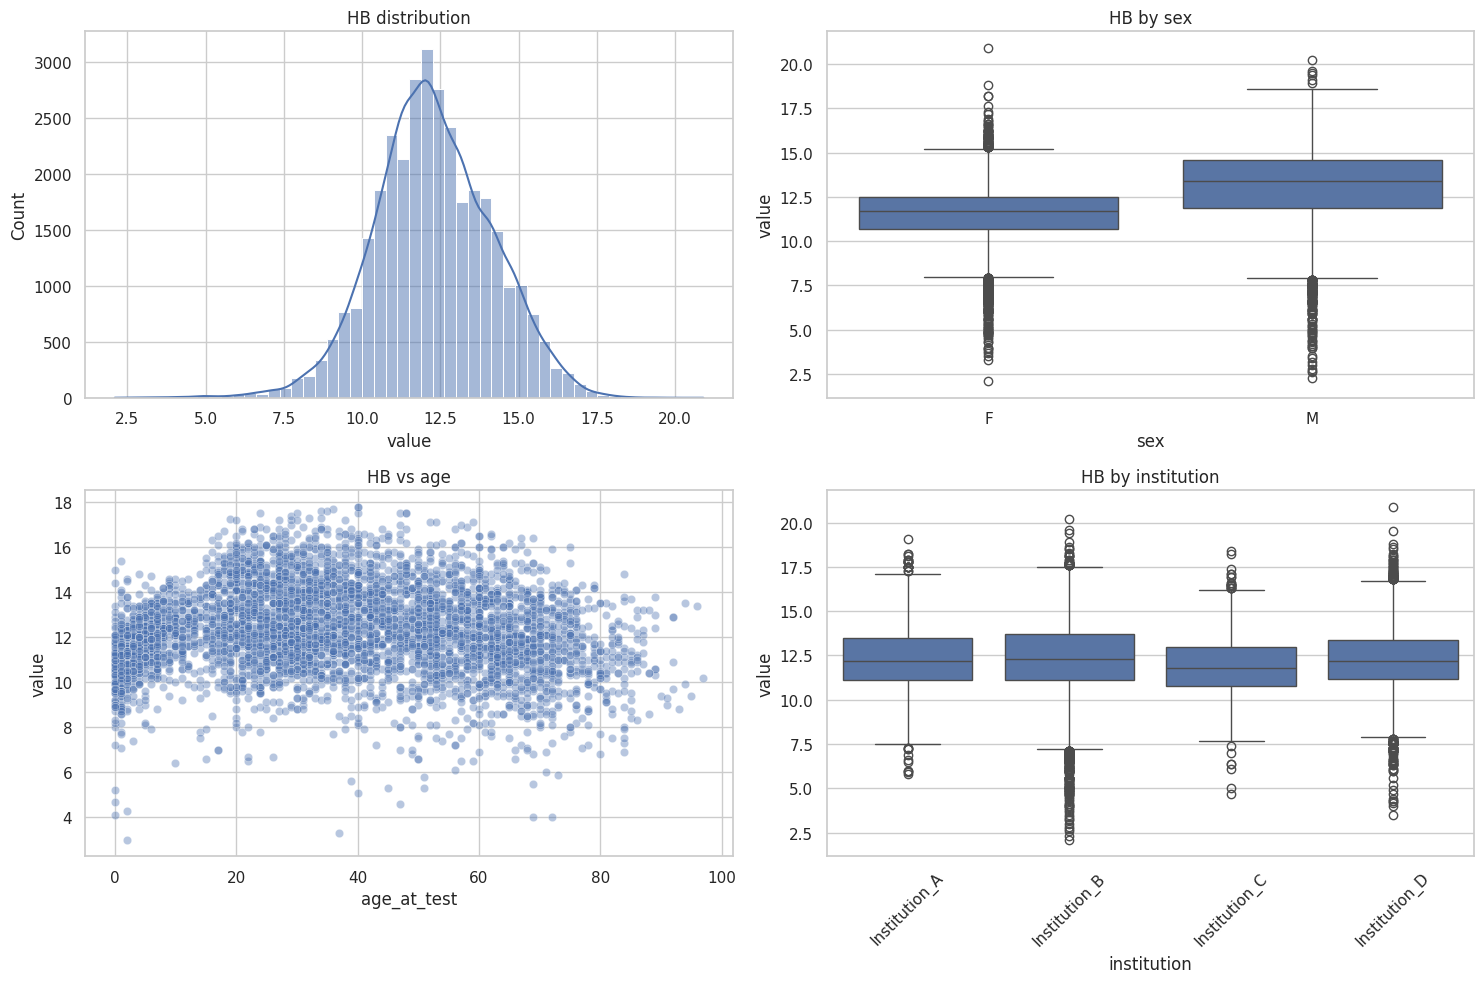

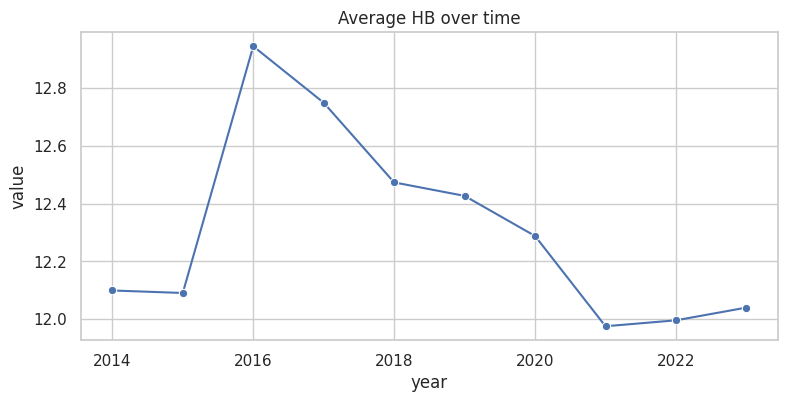

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(hb_data["value"], bins=50, kde=True, ax=ax[0, 0]); ax[0, 0].set_title("HB distribution")
sns.boxplot(data=hb_data, x="sex", y="value", ax=ax[0, 1]); ax[0, 1].set_title("HB by sex")
sns.scatterplot(data=hb_data.sample(min(5000, len(hb_data)), random_state=RANDOM_STATE),
                x="age_at_test", y="value", alpha=0.4, ax=ax[1, 0]); ax[1, 0].set_title("HB vs age")
sns.boxplot(data=hb_data, x="institution", y="value", ax=ax[1, 1]); ax[1, 1].set_title("HB by institution")
ax[1, 1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

yearly = hb_data.groupby("year")["value"].mean().reset_index()
plt.figure(figsize=(9, 4))
sns.lineplot(data=yearly, x="year", y="value", marker="o")
plt.title("Average HB over time"); plt.show()

In [ ]:
hb_data = hb_data.sort_values("bill_date").reset_index(drop=True)
X = hb_data[features]
y = hb_data[target]

split = int(len(hb_data) * 0.80)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", len(X_train), hb_data["bill_date"].iloc[0], "->", hb_data["bill_date"].iloc[split - 1])
print("Test :", len(X_test), hb_data["bill_date"].iloc[split], "->", hb_data["bill_date"].iloc[-1])

Train: 26329 2014-04-21 00:00:00 -> 2022-07-21 00:00:00
Test : 6583 2022-07-21 00:00:00 -> 2023-08-11 00:00:00


In [ ]:
def make_preprocessor():
    num = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, numeric_features),
                              ("cat", cat, categorical_features)])

def make_pipe(regressor):
    return Pipeline([("preprocessor", make_preprocessor()), ("model", regressor)])

In [ ]:
TUNE_ROWS = 40000
X_tune = X_train.iloc[-TUNE_ROWS:]
y_tune = y_train.iloc[-TUNE_ROWS:]
tscv = TimeSeriesSplit(n_splits=3)

def tune(name, regressor, param_grid, n_iter=8):
    t0 = time.time()
    search = RandomizedSearchCV(
        make_pipe(regressor),
        param_distributions={f"model__{k}": v for k, v in param_grid.items()},
        n_iter=n_iter, cv=tscv, scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE, n_jobs=1, refit=False)
    search.fit(X_tune, y_tune)
    best = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    print(f"{name}: CV RMSE={-search.best_score_:.4f} | {time.time()-t0:.0f}s | {best}")
    return best

best_rf = tune("Random Forest",
               RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
               {"n_estimators": [100, 200], "max_depth": [8, 12, 20],
                "min_samples_leaf": [1, 5, 10]})

best_xgb = tune("XGBoost",
                XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist"),
                {"n_estimators": [200, 400], "max_depth": [3, 5, 7],
                 "learning_rate": [0.03, 0.05, 0.1], "subsample": [0.8, 1.0]})

best_lgbm = tune("LightGBM",
                 LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1),
                 {"n_estimators": [200, 400], "max_depth": [3, 5, 7, -1],
                  "learning_rate": [0.03, 0.05, 0.1], "num_leaves": [15, 31, 63]})

best_cat = {"iterations": 300, "depth": 6, "learning_rate": 0.05}

Random Forest: CV RMSE=1.5239 | 64s | {'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 8}
XGBoost: CV RMSE=1.5231 | 11s | {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05}
LightGBM: CV RMSE=1.5167 | 7s | {'num_leaves': 15, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.03}


In [ ]:
def new_rf():   return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **best_rf)
def new_xgb():  return XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist", **best_xgb)
def new_lgbm(): return LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1, **best_lgbm)
def new_cat():  return CatBoostRegressor(random_seed=RANDOM_STATE, verbose=0, thread_count=-1,
                                         allow_writing_files=False, **best_cat)
def new_ann():  return MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                                    max_iter=300, early_stopping=True, random_state=RANDOM_STATE)

models = {
    # Baseline
    "Linear Regression": make_pipe(LinearRegression()),
    # BAGGING
    "Random Forest": make_pipe(new_rf()),
    "Bagging Regressor": make_pipe(BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=15, random_state=RANDOM_STATE),
        n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1)),
    "Extra Trees": make_pipe(ExtraTreesRegressor(
        n_estimators=100, max_depth=20, random_state=RANDOM_STATE, n_jobs=-1)),
    # BOOSTING
    "XGBoost": make_pipe(new_xgb()),
    "LightGBM": make_pipe(new_lgbm()),
    "CatBoost": make_pipe(new_cat()),
    # STACKING (n_jobs=None on purpose: nested parallelism can break pickling/saving)
    "Stacking": make_pipe(StackingRegressor(
        estimators=[("rf", new_rf()), ("xgb", new_xgb()),
                    ("lgbm", new_lgbm()), ("cat", new_cat())],
        final_estimator=RidgeCV(), cv=3, n_jobs=None)),
    # ANN
    "ANN": make_pipe(new_ann()),
    # HYBRID RF + ANN (equal-weight blend inside one sklearn object, so it is easy to save)
    "RF + ANN Hybrid": make_pipe(VotingRegressor(
        estimators=[("rf", new_rf()), ("ann", new_ann())], weights=[0.5, 0.5])),
}

In [ ]:
results, predictions, trained = [], {}, {}

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0

    t0 = time.time()
    pred = model.predict(X_test)
    pred_time = time.time() - t0

    trained[name], predictions[name] = model, pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100,
        "Training Time (sec)": fit_time,
        "Prediction Time (sec)": pred_time,
    })
    print(f"done: {name:20s} RMSE={results[-1]['RMSE']:.4f}  fit={fit_time:.1f}s")

done: Linear Regression    RMSE=1.7875  fit=0.1s
done: Random Forest        RMSE=1.5362  fit=4.7s
done: Bagging Regressor    RMSE=1.6480  fit=5.2s
done: Extra Trees          RMSE=1.7486  fit=4.1s
done: XGBoost              RMSE=1.5339  fit=0.3s
done: LightGBM             RMSE=1.5284  fit=0.2s
done: CatBoost             RMSE=1.5377  fit=1.3s
done: Stacking             RMSE=1.5352  fit=20.3s
done: ANN                  RMSE=2.7285  fit=4.0s
done: RF + ANN Hybrid      RMSE=1.9248  fit=9.1s


,Model,MAE,RMSE,R2,MAPE (%),Training Time (sec),Prediction Time (sec),Type
0,LightGBM,1.1366,1.5284,0.3552,10.4071,0.2432,0.0400,Boosting
1,XGBoost,1.1370,1.5339,0.3507,10.4147,0.3363,0.0298,Boosting
2,Stacking,1.1595,1.5352,0.3495,10.3773,20.2779,0.2103,Stacking
3,Random Forest,1.1512,1.5362,0.3487,10.4439,4.7041,0.1699,Bagging
4,CatBoost,1.1357,1.5377,0.3475,10.4493,1.3326,0.0282,Boosting
5,Bagging Regressor,1.2409,1.6480,0.2505,11.2358,5.1867,0.4402,Bagging
6,Extra Trees,1.3112,1.7486,0.1562,11.8834,4.0805,0.1095,Bagging
7,Linear Regression,1.3895,1.7875,0.1181,12.3042,0.0636,0.0178,Baseline
8,RF + ANN Hybrid,1.4798,1.9248,-0.0225,12.7827,9.1389,0.1493,Hybrid
9,ANN,2.0165,2.7285,-1.0547,17.0872,3.9916,0.0226,Baseline


Best model overall (lowest RMSE): LightGBM


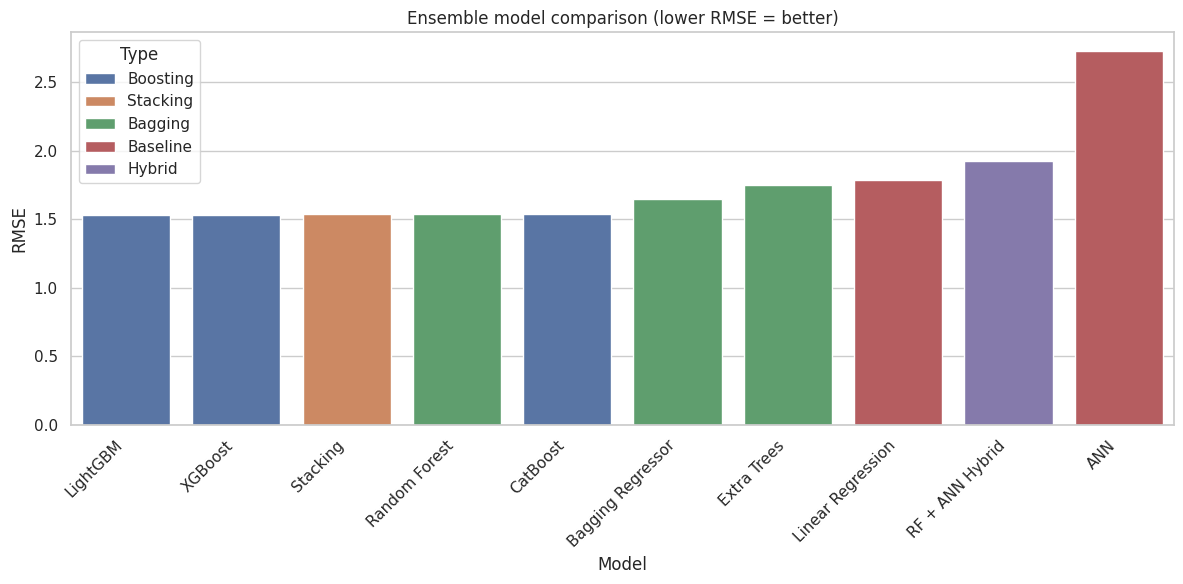

In [ ]:
bagging_set = {"Random Forest", "Bagging Regressor", "Extra Trees"}
boosting_set = {"XGBoost", "LightGBM", "CatBoost"}
def family(m):
    if m in bagging_set: return "Bagging"
    if m in boosting_set: return "Boosting"
    if m == "Stacking": return "Stacking"
    if "Hybrid" in m: return "Hybrid"
    return "Baseline"

final_results = pd.DataFrame(results)
final_results["Type"] = final_results["Model"].map(family)
final_results = final_results.sort_values("RMSE").reset_index(drop=True)
display(final_results.round(4))

best_model_name = final_results.iloc[0]["Model"]
print("Best model overall (lowest RMSE):", best_model_name)

plt.figure(figsize=(12, 6))
sns.barplot(data=final_results, x="Model", y="RMSE", hue="Type", dodge=False)
plt.xticks(rotation=45, ha="right")
plt.title("Ensemble model comparison (lower RMSE = better)")
plt.tight_layout(); plt.show()

In [ ]:
rf_vs_gb = final_results[final_results["Model"].isin(
    ["Random Forest", "XGBoost", "LightGBM", "CatBoost"])]
display(rf_vs_gb[["Model", "MAE", "RMSE", "R2", "MAPE (%)", "Training Time (sec)"]].round(4))
print("Best of RF vs boosting:", rf_vs_gb.iloc[0]["Model"])
print("Hybrid RF+ANN vs RF alone  -> RMSE:",
      round(final_results.set_index("Model").loc["RF + ANN Hybrid", "RMSE"], 4), "vs",
      round(final_results.set_index("Model").loc["Random Forest", "RMSE"], 4))


,Model,MAE,RMSE,R2,MAPE (%),Training Time (sec)
0,LightGBM,1.1366,1.5284,0.3552,10.4071,0.2432
1,XGBoost,1.1370,1.5339,0.3507,10.4147,0.3363
3,Random Forest,1.1512,1.5362,0.3487,10.4439,4.7041
4,CatBoost,1.1357,1.5377,0.3475,10.4493,1.3326


Best of RF vs boosting: LightGBM
Hybrid RF+ANN vs RF alone  -> RMSE: 1.9248 vs 1.5362


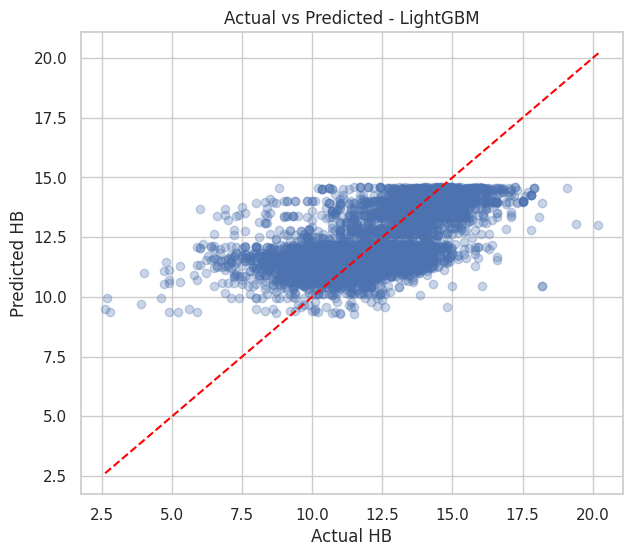

In [ ]:
best_pred = predictions[best_model_name]
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.3)
lo, hi = min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())
plt.plot([lo, hi], [lo, hi], "--", color="red")
plt.xlabel("Actual HB"); plt.ylabel("Predicted HB")
plt.title(f"Actual vs Predicted - {best_model_name}")
plt.show()

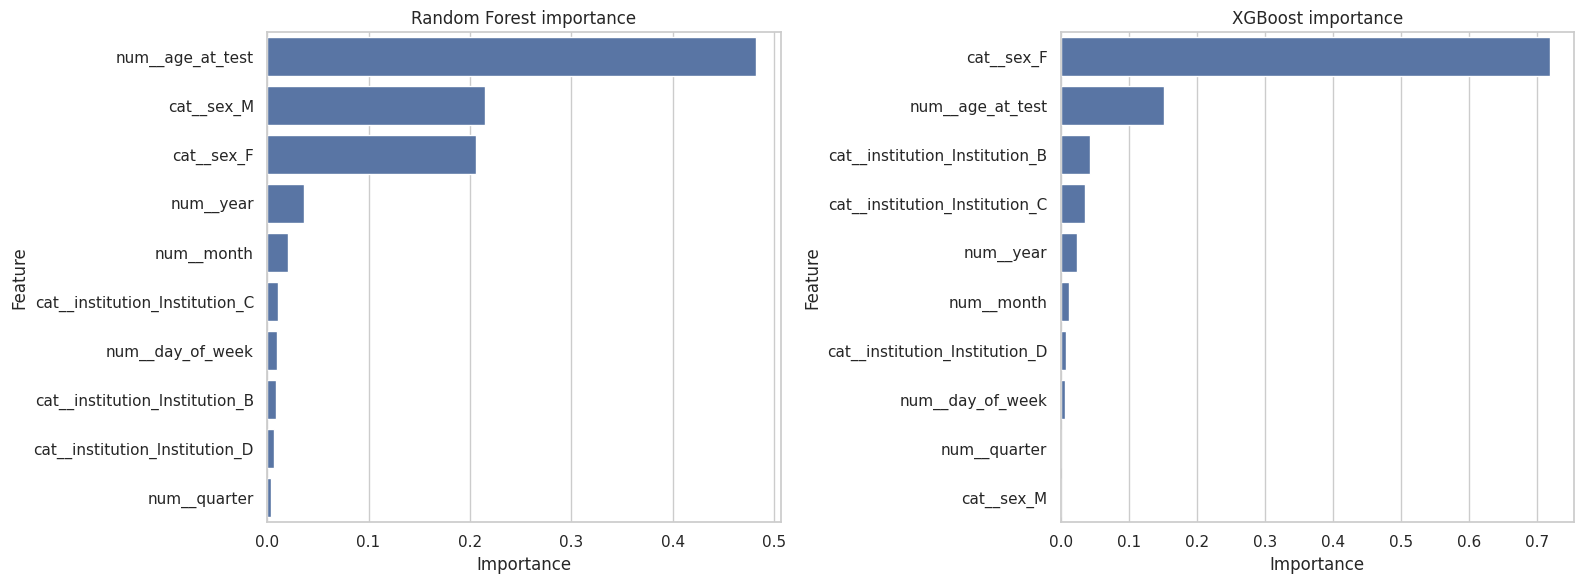

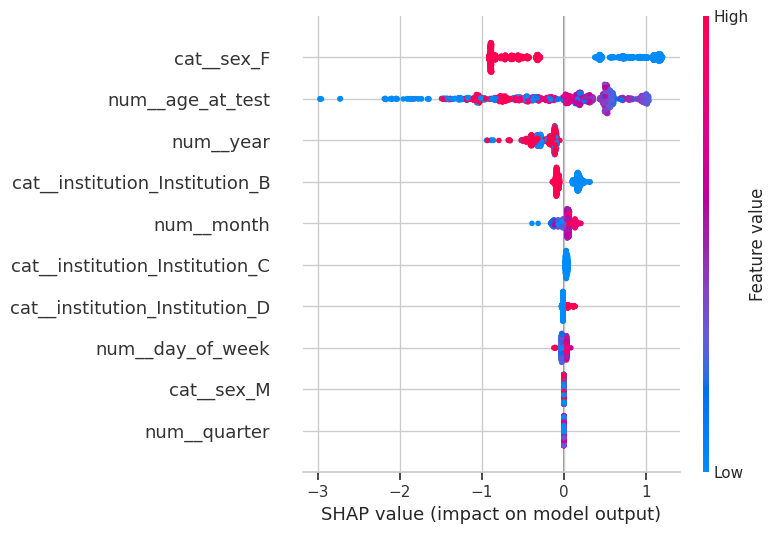

In [ ]:
def importance_df(pipe):
    names = pipe.named_steps["preprocessor"].get_feature_names_out()
    imp = pipe.named_steps["model"].feature_importances_
    return pd.DataFrame({"Feature": names, "Importance": imp}).sort_values("Importance", ascending=False)

rf_imp = importance_df(trained["Random Forest"])
xgb_imp = importance_df(trained["XGBoost"])

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=rf_imp.head(15), x="Importance", y="Feature", ax=ax[0]); ax[0].set_title("Random Forest importance")
sns.barplot(data=xgb_imp.head(15), x="Importance", y="Feature", ax=ax[1]); ax[1].set_title("XGBoost importance")
plt.tight_layout(); plt.show()

try:
    import shap
    xgb_pipe = trained["XGBoost"]
    sample = X_test.sample(min(1000, len(X_test)), random_state=RANDOM_STATE)
    Xt = xgb_pipe.named_steps["preprocessor"].transform(sample)
    names = xgb_pipe.named_steps["preprocessor"].get_feature_names_out()
    explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
    shap_values = explainer.shap_values(Xt)
    shap.summary_plot(shap_values, Xt, feature_names=names)
except Exception as e:
    print("SHAP skipped:", e)

In [ ]:
SAVE_DIR = "saved_models"
shutil.rmtree(SAVE_DIR, ignore_errors=True)
os.makedirs(SAVE_DIR)

def fname(name):
    return name.lower().replace(" + ", "_and_").replace(" ", "_").replace("/", "_") + ".pkl"

check_X = X_test.iloc[:200]
save_report = []

for name, model in trained.items():
    path = os.path.join(SAVE_DIR, fname(name))
    joblib.dump(model, path, compress=3)
    # Verify: reload from disk and compare predictions
    reloaded = joblib.load(path)
    ok = np.allclose(reloaded.predict(check_X), model.predict(check_X), atol=1e-6)
    size_mb = os.path.getsize(path) / 1e6
    save_report.append({"Model": name, "File": fname(name), "Size (MB)": round(size_mb, 2), "Reload OK": ok})

display(pd.DataFrame(save_report))
assert all(r["Reload OK"] for r in save_report), "A model failed the reload check!"

# Extra, version-safe copy of XGBoost (native format, never corrupts across versions)
trained["XGBoost"].named_steps["model"].save_model(os.path.join(SAVE_DIR, "xgboost_native.json"))
joblib.dump(trained["XGBoost"].named_steps["preprocessor"],
            os.path.join(SAVE_DIR, "xgboost_preprocessor.pkl"), compress=3)

# Results + data needed by the dashboard
final_results.to_csv(os.path.join(SAVE_DIR, "model_comparison.csv"), index=False)
joblib.dump(final_results, os.path.join(SAVE_DIR, "model_comparison.pkl"))

pred_df = pd.DataFrame({"actual": y_test.values})
for name, p in predictions.items():
    pred_df[name] = p
pred_df.to_csv(os.path.join(SAVE_DIR, "test_predictions.csv"), index=False)

rf_imp.to_csv(os.path.join(SAVE_DIR, "rf_feature_importance.csv"), index=False)
xgb_imp.to_csv(os.path.join(SAVE_DIR, "xgb_feature_importance.csv"), index=False)
hb_data.to_csv(os.path.join(SAVE_DIR, "hb_clean.csv"), index=False)

meta = {
    "features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "institutions": sorted(hb_data["institution"].unique().tolist()),
    "sex_values": sorted(hb_data["sex"].unique().tolist()),
    "age_min": float(hb_data["age_at_test"].min()),
    "age_max": float(hb_data["age_at_test"].max()),
    "best_model": best_model_name,
    "best_params": {"rf": best_rf, "xgb": best_xgb, "lgbm": best_lgbm, "cat": best_cat},
    "versions": {"sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
                 "lightgbm": lightgbm.__version__, "catboost": catboost.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "joblib": joblib.__version__},
}
with open(os.path.join(SAVE_DIR, "metadata.json"), "w") as f:
    json.dump(meta, f, indent=2)

# requirements.txt with the EXACT versions used for training
with open(os.path.join(SAVE_DIR, "requirements.txt"), "w") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}\n"
            f"lightgbm=={lightgbm.__version__}\ncatboost=={catboost.__version__}\n"
            f"numpy=={np.__version__}\npandas=={pd.__version__}\njoblib=={joblib.__version__}\n"
            "streamlit\nplotly\nshap\n")
print("All files saved and verified.")

,Model,File,Size (MB),Reload OK
0,Linear Regression,linear_regression.pkl,0.00,True
1,Random Forest,random_forest.pkl,1.93,True
2,Bagging Regressor,bagging_regressor.pkl,9.22,True
3,Extra Trees,extra_trees.pkl,60.67,True
4,XGBoost,xgboost.pkl,0.05,True
5,LightGBM,lightgbm.pkl,0.05,True
6,CatBoost,catboost.pkl,0.13,True
7,Stacking,stacking.pkl,2.16,True
8,ANN,ann.pkl,0.07,True
9,RF + ANN Hybrid,rf_and_ann_hybrid.pkl,2.00,True


All files saved and verified.


In [ ]:
st = trained["Stacking"]
stk = st.named_steps["model"]
folder = "saved_models/stacking_parts"
os.makedirs(folder, exist_ok=True)

joblib.dump(st.named_steps["preprocessor"], f"{folder}/preprocessor.pkl", compress=3)
joblib.dump(stk.final_estimator_, f"{folder}/final.pkl", compress=3)

for (name, _), est in zip(stk.estimators, stk.estimators_):
    if name == "xgb":
        est.save_model(f"{folder}/xgb.json")
    else:
        joblib.dump(est, f"{folder}/{name}.pkl", compress=3)

# XGBoost alone is already saved as saved_models/xgboost_native.json
shutil.make_archive("saved_models", "zip", "saved_models")
files.download("saved_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
hyb = trained["RF + ANN Hybrid"]
pre = hyb.named_steps["preprocessor"]
voter = hyb.named_steps["model"]
joblib.dump(Pipeline([("preprocessor", pre), ("model", voter.named_estimators_["rf"])]),
            "saved_models/hybrid_rf.pkl", compress=3)
joblib.dump(Pipeline([("preprocessor", pre), ("model", voter.named_estimators_["ann"])]),
            "saved_models/hybrid_ann.pkl", compress=3)
print("hybrid files saved")

hybrid files saved


In [ ]:
zip_path = shutil.make_archive("saved_models", "zip", SAVE_DIR)
md5 = hashlib.md5(open(zip_path, "rb").read()).hexdigest()
print("ZIP size (MB):", round(os.path.getsize(zip_path) / 1e6, 2), "| MD5:", md5)
print("Files:", os.listdir(SAVE_DIR))
files.download("saved_models.zip")

ZIP size (MB): 77.84 | MD5: 1bacea086676184e89ab6764a0fb5311
Files: ['model_comparison.csv', 'hybrid_rf.pkl', 'catboost.pkl', 'rf_feature_importance.csv', 'xgb_feature_importance.csv', 'test_predictions.csv', 'metadata.json', 'xgboost_native.json', 'hb_clean.csv', 'ann.pkl', 'stacking.pkl', 'hybrid_ann.pkl', 'requirements.txt', 'linear_regression.pkl', 'bagging_regressor.pkl', 'extra_trees.pkl', 'random_forest.pkl', 'xgboost_preprocessor.pkl', 'lightgbm.pkl', 'rf_and_ann_hybrid.pkl', 'model_comparison.pkl', 'xgboost.pkl']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile
with zipfile.ZipFile("saved_models.zip") as z:
    print("ZIP test (None = OK):", z.testzip())
test_model = joblib.load(os.path.join(SAVE_DIR, "stacking.pkl"))
print("Stacking reload prediction sample:", test_model.predict(X_test.iloc[:3]))
test_xgb = joblib.load(os.path.join(SAVE_DIR, "xgboost.pkl"))
print("XGBoost reload prediction sample :", test_xgb.predict(X_test.iloc[:3]))

ZIP test (None = OK): None
Stacking reload prediction sample: [10.41913376 13.20598279 11.21911016]
XGBoost reload prediction sample : [10.643439 13.348837 11.456264]


In [ ]:
joblib.dump({"X_test": X_test, "y_test": y_test}, "saved_models/test_data.pkl")
files.download("saved_models/test_data.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>